# 01. Data preparation
Messy Online Retail II file → audited and cleaned data → churn label and features.

**Output:** `data/processed/` gets `sales_clean.csv`, `returns.csv`, `cleaning_log.csv`,
`features_train.csv` and `features_test.csv`.

**Churn definition:** a customer churns if they make no purchase in the 90 days after a cutoff
date. Features use only data *before* the cutoff. We build two snapshots: a June 2011 cutoff
to train on, and a September 2011 cutoff to test on (the future, as in real life).

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from churn_utils import build_features, TRAIN_CUTOFF, TEST_CUTOFF

RAW = Path("C:/Nancy/Churn_Project/data/raw/online+retail+ii/online_retail_II.xlsx")     # change if your file is somewhere else
OUT = Path("data/processed")
OUT.mkdir(parents=True, exist_ok=True)

## 1. Load both sheets (2009-2010 and 2010-2011)

In [2]:
raw = pd.concat(pd.read_excel(RAW, sheet_name=None, engine="openpyxl").values(), ignore_index=True)
print(raw.shape)
raw.head()

(1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


## 2. Audit before cleaning

In [3]:
print("Missing values:\n", raw.isna().sum(), "\n")
print("Exact duplicate rows      :", raw.duplicated().sum())
print("Zero/negative quantity    :", (raw["Quantity"] <= 0).sum())
print("Zero/negative price       :", (raw["Price"] <= 0).sum())
print("Cancelled invoices ('C')  :", raw["Invoice"].astype(str).str.startswith("C").sum())
print(f"Missing Customer ID share : {raw['Customer ID'].isna().mean():.1%}")

Missing values:
 Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64 

Exact duplicate rows      : 34335
Zero/negative quantity    : 22950
Zero/negative price       : 6207
Cancelled invoices ('C')  : 19494
Missing Customer ID share : 22.8%


## 3. Clean (every step is logged)
This cell starts from `raw.copy()`, so it is safe to re-run.

In [4]:
df = raw.copy()
df = df.rename(columns={"Invoice": "invoice", "StockCode": "stock_code", "Description": "description",
                        "Quantity": "quantity", "InvoiceDate": "invoice_date", "Price": "price",
                        "Customer ID": "customer_id", "Country": "country"})
for c in ["invoice", "stock_code"]:
    df[c] = df[c].astype(str).str.strip().str.upper()
df["description"] = df["description"].astype("string").str.strip().str.upper()
df["invoice_date"] = pd.to_datetime(df["invoice_date"], errors="coerce")

log = []
def step(name, before, after, note=""):
    log.append({"step": name, "rows_before": before, "rows_after": after,
                "rows_removed": before - after, "note": note})

step("raw rows", len(df), len(df))

n = len(df); df = df.dropna(subset=["invoice_date"]); step("drop invalid dates", n, len(df))
n = len(df); df = df.drop_duplicates();               step("drop exact duplicates", n, len(df))

# Non-product rows: postage, fees, manual adjustments, samples, test entries, gift vouchers
NON_PRODUCT = r"^(POST|D|M|BANK CHARGES|C2|DOT|CRUK|PADS|S|B|AMAZONFEE|ADJUST2?|TEST\d+|SP1002)$"
n = len(df)
df = df[~(df["stock_code"].str.match(NON_PRODUCT) | df["stock_code"].str.startswith("GIFT_"))]
step("drop non-product stock codes", n, len(df))

# Cancellations (invoice starts with 'C') are kept in a separate returns table
is_cancel = df["invoice"].str.startswith("C")
returns, df = df[is_cancel].copy(), df[~is_cancel].copy()
step("move cancellations to returns table", len(df) + len(returns), len(df), f"{len(returns):,} rows")

n = len(df); df = df[(df["quantity"] > 0) & (df["price"] > 0)]; step("drop quantity<=0 or price<=0", n, len(df))

# Guest checkouts have no Customer ID, so they cannot be tracked for churn
n = len(df)
df = df.dropna(subset=["customer_id"]).copy()
returns = returns.dropna(subset=["customer_id"]).copy()
step("drop missing Customer ID", n, len(df), "guest checkouts")
df["customer_id"] = df["customer_id"].astype(int)
returns["customer_id"] = returns["customer_id"].astype(int)

# One clean description per stock code, revenue, and an outlier flag (flagged, not dropped)
best_desc = (df.dropna(subset=["description"]).groupby("stock_code")["description"]
               .agg(lambda s: s.mode().iloc[0]))
for t in (df, returns):
    t["description"] = t["stock_code"].map(best_desc)
    t["revenue"] = t["quantity"] * t["price"]
df["is_outlier"] = ((df["revenue"] > df["revenue"].quantile(0.999))
                    | (df["quantity"] > df["quantity"].quantile(0.999)))

assert (df["quantity"] > 0).all() and (df["price"] > 0).all() and df["customer_id"].notna().all()
log_df = pd.DataFrame(log)
print(log_df.to_string(index=False))
print(f"\nFinal: {len(df):,} lines | {df['customer_id'].nunique():,} customers | "
      f"{df['invoice'].nunique():,} invoices | {df['stock_code'].nunique():,} products | "
      f"revenue {df['revenue'].sum():,.0f}")
print("Date range:", df["invoice_date"].min(), "->", df["invoice_date"].max())

df.to_csv(OUT / "sales_clean.csv", index=False)
returns.to_csv(OUT / "returns.csv", index=False)
log_df.to_csv(OUT / "cleaning_log.csv", index=False)

                               step  rows_before  rows_after  rows_removed            note
                           raw rows      1067371     1067371             0                
                 drop invalid dates      1067371     1067371             0                
              drop exact duplicates      1067371     1033036         34335                
       drop non-product stock codes      1033036     1027215          5821                
move cancellations to returns table      1027215     1009301         17914     17,914 rows
       drop quantity<=0 or price<=0      1009301     1003338          5963                
           drop missing Customer ID      1003338      776577        226761 guest checkouts

Final: 776,577 lines | 5,852 customers | 36,594 invoices | 4,619 products | revenue 17,068,568
Date range: 2009-12-01 07:45:00 -> 2011-12-09 12:50:00


## 4. Quick EDA

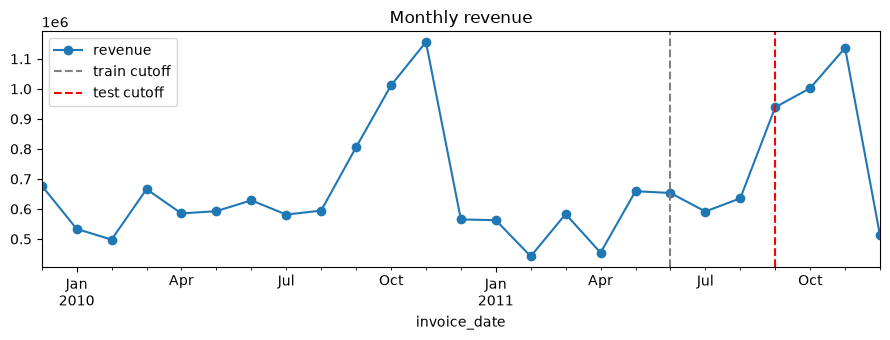

count    5852.0
mean        6.3
std        12.7
min         1.0
25%         1.0
50%         3.0
75%         7.0
max       373.0
Name: invoice, dtype: float64


In [5]:
monthly = df.set_index("invoice_date").resample("MS")["revenue"].sum()
ax = monthly.plot(figsize=(9, 3.5), marker="o", title="Monthly revenue")
ax.axvline(TRAIN_CUTOFF, color="grey", linestyle="--", label="train cutoff")
ax.axvline(TEST_CUTOFF, color="red", linestyle="--", label="test cutoff")
ax.legend()
plt.tight_layout()
plt.show()
print(df.groupby("customer_id")["invoice"].nunique().describe().round(1))

## 5. Features and churn label at two snapshots

In [6]:
train = build_features(df, returns, TRAIN_CUTOFF)
test = build_features(df, returns, TEST_CUTOFF)
print(f"Train snapshot ({TRAIN_CUTOFF.date()}): {len(train):,} customers, churn rate {train['churn'].mean():.1%}")
print(f"Test  snapshot ({TEST_CUTOFF.date()}): {len(test):,} customers, churn rate {test['churn'].mean():.1%}")

train.to_csv(OUT / "features_train.csv")
test.to_csv(OUT / "features_test.csv")

key = ["recency_days", "frequency", "monetary", "avg_gap_days", "orders_last_90d", "return_rate", "tenure_days"]
print("\nMean of key features by churn (test snapshot):")
print(test.groupby("churn")[key].mean().round(2).T)

Train snapshot (2011-06-10): 4,944 customers, churn rate 68.0%
Test  snapshot (2011-09-09): 5,253 customers, churn rate 56.6%

Mean of key features by churn (test snapshot):
churn                  0        1
recency_days      119.77   271.48
frequency           9.17     3.05
monetary         4545.07  1113.38
avg_gap_days       75.06   108.19
orders_last_90d     1.36     0.26
return_rate         0.02     0.03
tenure_days       439.60   422.51
